# Total Vehicle Crime In Relation To Speeding And Red Light Violations

This notebook compares the amount of vehicle crime in Chicago to the amount of speeding and red light violations that have been documented between July 2014 and August 2026.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

The scales between total vehicle crime, red light violations, and speeding violations are too great. To show the growth in each variable over the years, I first show the counts and lines separately, and then show a plot with their trends in relation to each other.

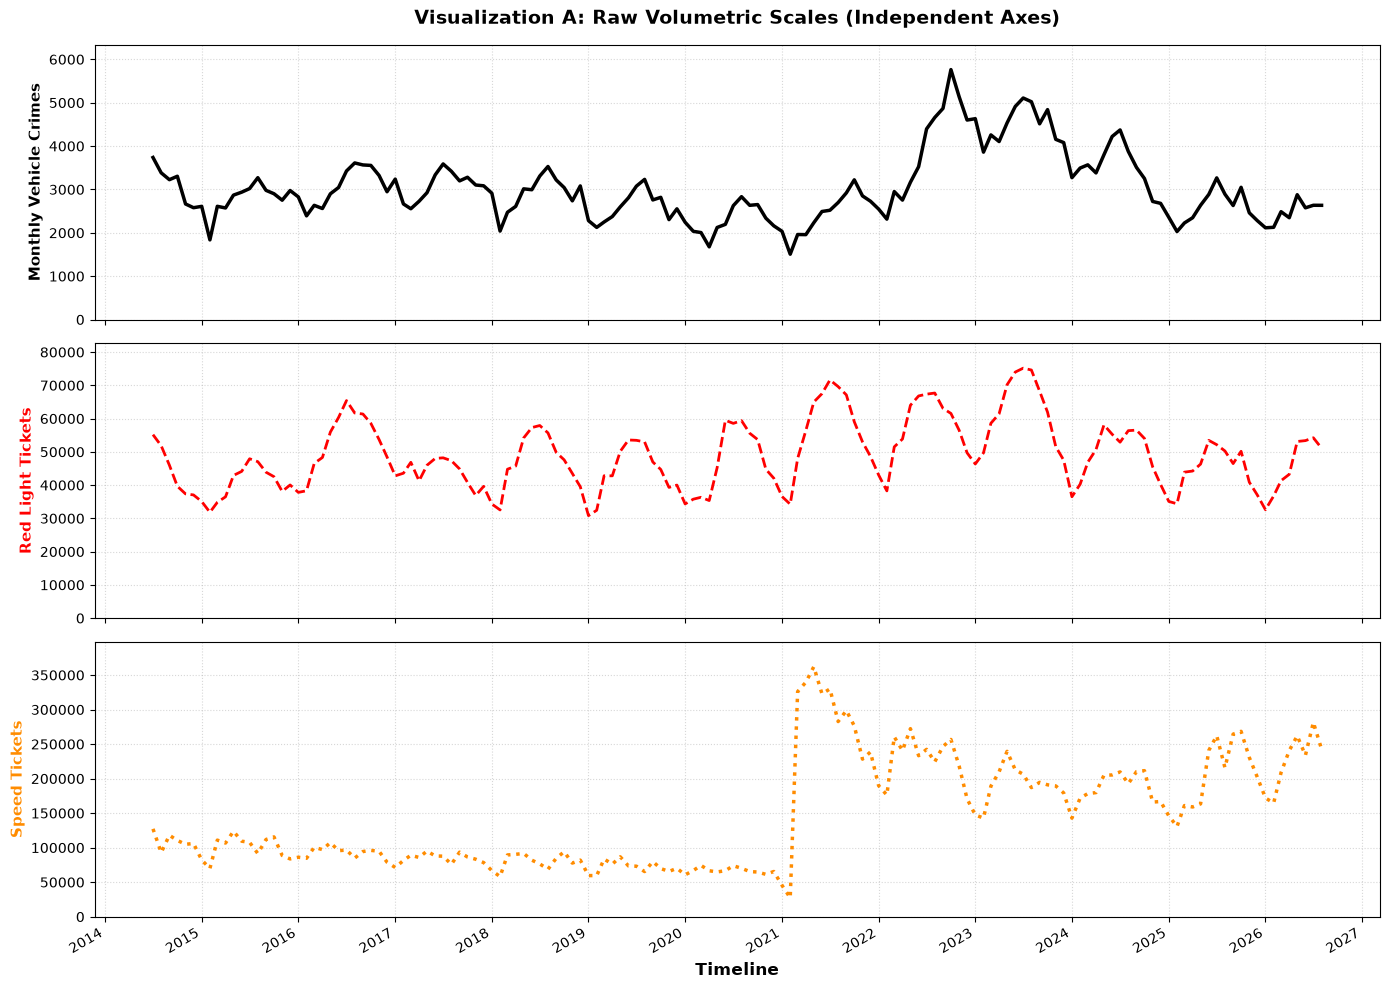

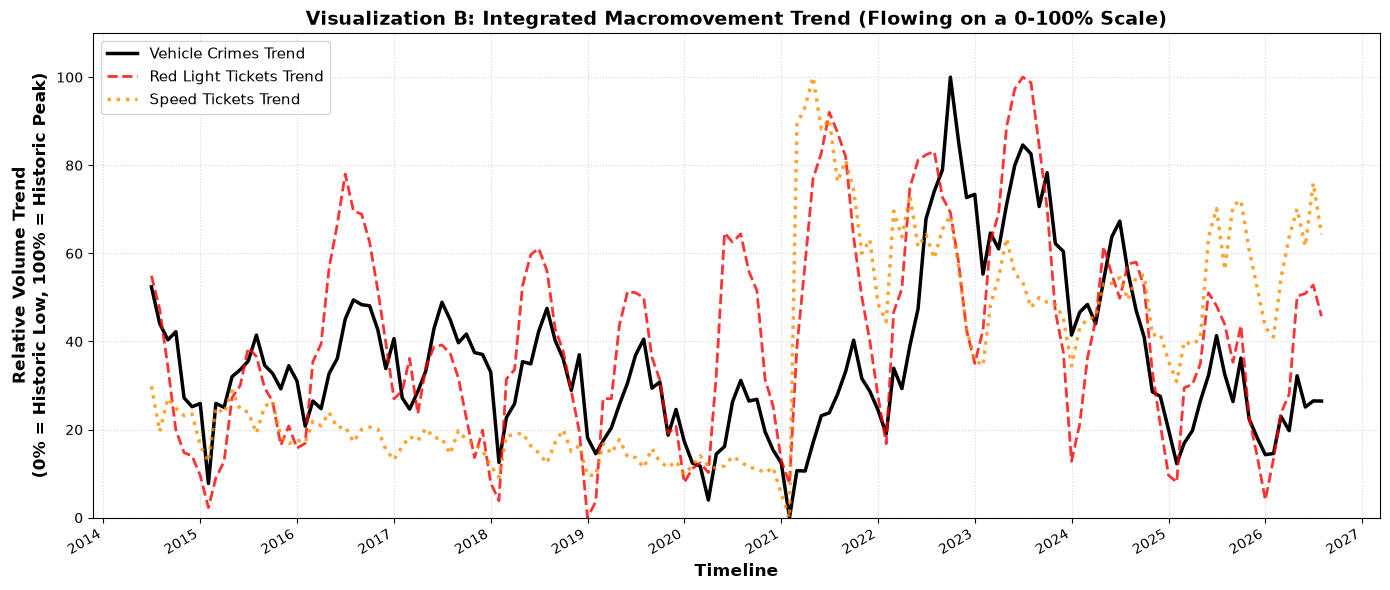

In [2]:
# =================================================================
# 1. READ INDEPENDENT FILES AND MERGE FOR PLOTTING
# =================================================================
crime_df = pd.read_csv("Clean_Monthly_Crimes.csv")
red_df = pd.read_csv("Clean_Monthly_Red_Light.csv")
speed_df = pd.read_csv("Clean_Monthly_Speed.csv")

# Merge them sequentially on their standardized string Timestamps
master_df = crime_df.merge(red_df, on='Timestamp', how='outer')
master_df = master_df.merge(speed_df, on='Timestamp', how='outer').fillna(0)

# Convert string timestamps back into active datetime objects for mapping the horizontal axis
master_df['Timestamp'] = pd.to_datetime(master_df['Timestamp'])

# =================================================================
# VISUALIZATION 1: THE 3-PANEL STACKED SUBPLOTS (RAW VOLUMES)
# =================================================================
fig1, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Panel 1: Crimes (Small Scale)
ax1.plot(master_df['Timestamp'], master_df['Total_Vehicle_Crimes'], color='black', linewidth=2.5)
ax1.set_ylabel('Monthly Vehicle Crimes', fontsize=11, fontweight='bold', color='black')
ax1.set_ylim(0, master_df['Total_Vehicle_Crimes'].max() * 1.1)
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.set_title('Visualization A: Raw Volumetric Scales (Independent Axes)', fontsize=14, fontweight='bold', pad=15)

# Panel 2: Red Light Violations (Medium Scale)
ax2.plot(master_df['Timestamp'], master_df['Red_Light_Tickets'], color='red', linestyle='--', linewidth=2)
ax2.set_ylabel('Red Light Tickets', fontsize=11, fontweight='bold', color='red')
ax2.set_ylim(0, master_df['Red_Light_Tickets'].max() * 1.1)
ax2.grid(True, linestyle=':', alpha=0.5)

# Panel 3: Speed Violations (Large Scale)
ax3.plot(master_df['Timestamp'], master_df['Speed_Tickets'], color='darkorange', linestyle=':', linewidth=2.5)
ax3.set_ylabel('Speed Tickets', fontsize=11, fontweight='bold', color='darkorange')
ax3.set_ylim(0, master_df['Speed_Tickets'].max() * 1.1)
ax3.grid(True, linestyle=':', alpha=0.5)
ax3.set_xlabel('Timeline', fontsize=12, fontweight='bold')

# Configure X-axis dates
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig1.autofmt_xdate()
plt.tight_layout()

# =================================================================
# VISUALIZATION 2: THE UNIFIED TREND GRAPH (FLOWING TOGETHER)
# =================================================================
fig2, ax = plt.subplots(figsize=(14, 6))

# Plot all three normalized lines flowing together on a single grid scale
ax.plot(master_df['Timestamp'], master_df['Crime_Norm'], 
        color='black', label='Vehicle Crimes Trend', linewidth=2.5)
ax.plot(master_df['Timestamp'], master_df['Red_Light_Norm'], 
        color='red', linestyle='--', alpha=0.8, label='Red Light Tickets Trend', linewidth=2)
ax.plot(master_df['Timestamp'], master_df['Speed_Norm'], 
        color='darkorange', linestyle=':', alpha=0.8, label='Speed Tickets Trend', linewidth=2.5)

# Formatting the single unified scale
ax.set_xlabel('Timeline', fontsize=12, fontweight='bold')
ax.set_ylabel('Relative Volume Trend\n(0% = Historic Low, 100% = Historic Peak)', fontsize=12, fontweight='bold')
ax.set_ylim(0, 110) 
ax.grid(True, linestyle=':', alpha=0.5)

# Synchronize major year intervals
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig2.autofmt_xdate()

# Titles and Legends
plt.title('Visualization B: Integrated Macromovement Trend (Flowing on a 0-100% Scale)', fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=11)
plt.tight_layout()

plt.show()

## So What?

The initial 3 plots are to show that the data are in three totally different scales. Vehicle crimes are small (usually under 5k/month), red-light tickets are medium (hover ~50k/month), and speed tickets are massive (spike past 250K/month). This matters because it means a single normal graph scale is not useful, or the speed tickets would crush the vehicle crime trend line flat. The huge speed ticket explosion in 2021 is completely unexpected at first. There must be some change in the way that speeding violations are tracked for the spike and the new average that the speeding violation amount hovers around(~220K).

The final plot puts the three lines on a scale of 0-100% to see them flow together and observe how the trends for traffic tickets and vehicle crimes move together or independently. There seems to be little or no correlation between total vehicle crimes and speeding and red light violations. The center of the plot may just be a big anomaly because of COVID, since the trend in the years before and after quarantine line up a little bit.

## What's Next?

The next data the chart could be breaking away from the trend graphs to plots that address Chicago districts or wards. To see if crimes are dropping locally in areas that have a high density of cameras, or if the trends remain disconnected even on a smaller scale. And or find a downloadable dataset that maps the number of active Flock cameras over time to plot against the crime line, rather than comparing to the trend with traffic ticket cameras.

As for the research question, "Does the presence of Flock cameras impact the amount of crimes, or more specifically, traffic violations, in Chicago?", it has shifted to "Does the local density of Flock cameras in specific Chicago police districts correspond to a drop in vehicle crimes?". Looking at the final plot, the citywide sum of the values for vehicle crime and traffic violations doesn't show a clear connection between them, maybe looking at a closer scale will show some correlation between Flock cameras and crime.